# Giai đoạn 1–3: Thu thập đa nguồn, Chuẩn hóa 35 nhãn & EDA

Quy trình thực hiện trong notebook này trên dữ liệu thu thập từ **4 nguồn** (`webtruyen.vn`, `truyenfull.live`, `metruyenchu.com.vn`, `webnovel.vn`):
1. Đọc 4 tệp dữ liệu thô (`webtruyen_raw.csv`: `55.684`, `truyenfull_raw.csv`: `2.400`, `metruyenchu_raw.csv`: `420`, `webnovel_raw.csv`: `247`) $\rightarrow$ tổng **`58.751` bản ghi thô**.
2. Áp dụng `deduplicate_stories()` (loại trùng tên `title` và trùng `summary` kèm gộp thẻ `genres_raw` $\rightarrow$ **`20.963` truyện duy nhất**, loại `37.788` bản ghi trùng) và loại `111` bản ghi không còn nhãn hợp lệ (chủ yếu sách phi hư cấu từ `webnovel.vn` và `4` truyện chỉ gắn thẻ nguồn gốc địa lý), thu được **`20.852` truyện hợp lệ** (`webtruyen.vn`: `18.230`, `truyenfull.live`: `2.069`, `metruyenchu.com.vn`: `418`, `webnovel.vn`: `135`).
3. Chuẩn hóa **42 thẻ gốc $\rightarrow$ 35 nhãn chuẩn** (`GENRE_LABELS`): giữ độc lập `32` thể loại (`Nữ Phụ`, `Thám Hiểm`, `Khác`, `Tiểu Thuyết`, `Đoản Văn`, `Dị Năng`, `Mạt Thế`, `Khoa Huyễn`, `Cung Đấu`, `Gia Đấu`, `Quân Sự`, `Quan Trường`...), chuẩn hóa `Truyện Teen` thành `hoc_duong`, chỉ gộp `3` cặp đồng trục ngữ nghĩa và loại `4` thẻ nguồn gốc địa lý; xuất ra **`data/processed/stories.csv`** (`20.852` dòng × `49` cột).
4. Thực hiện EDA đa nhãn: `label cardinality = 3.0601`, `label density = 0.0874`, độ dài `summary` (`min=15`, `mean=205.90`, `median=161`, `max=3.598`), ma trận đồng xuất hiện `35×35` và biểu đồ `outputs/figures/eda_overview.png`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.config import (
    ACTIVE_RAW_CSVS,
    FIGURES_DIR,
    GENRE_DISPLAY_NAMES,
    GENRE_LABELS,
    MIN_SUMMARY_WORDS,
    STORIES_CSV,
)
from src.crawl.merge_data import REQUIRED_RAW_COLUMNS, deduplicate_stories, normalize_genres

raw_files = [p for p in ACTIVE_RAW_CSVS if p.exists()]
frames = []
for csv_path in raw_files:
    part_df = pd.read_csv(csv_path, encoding="utf-8")
    print(f"Đọc {csv_path.name:22s}: {len(part_df):5d} bản ghi")
    frames.append(part_df)

df_raw = pd.concat(frames, ignore_index=True)
print(f"\nTổng số bản ghi thô đa nguồn trước khi lọc: {len(df_raw)}")
df_raw[["id", "title", "genres_raw", "source"]].head()


Đọc webtruyen_raw.csv     : 55684 bản ghi
Đọc truyenfull_raw.csv    :  2400 bản ghi
Đọc metruyenchu_raw.csv   :   420 bản ghi
Đọc webnovel_raw.csv      :   247 bản ghi

Tổng số bản ghi thô đa nguồn trước khi lọc: 58751


,id,title,genres_raw,source
0,WT_0001,Con Đường Bá Chủ,Tiên Hiệp|Cổ Đại|Huyền Huyễn,webtruyen.vn
1,WT_0002,Mục Thần Ký,Tiên Hiệp|Huyền Huyễn,webtruyen.vn
2,WT_0003,Vô Thượng Sát Thần,Tiên Hiệp|Xuyên Không,webtruyen.vn
3,WT_0004,Thần Đạo Đan Tôn,Tiên Hiệp|Huyền Huyễn|Trọng Sinh,webtruyen.vn
4,WT_0005,Tiên Nghịch,Tiên Hiệp|Kiếm Hiệp|Huyền Huyễn,webtruyen.vn


In [2]:
# Chuẩn hóa các cột bắt buộc, loại trùng lặp tên truyện/summary và lọc bài quá ngắn
df_merged = df_raw.copy()
for col in REQUIRED_RAW_COLUMNS:
    if col not in df_merged.columns:
        df_merged[col] = ""

n_before = len(df_merged)
df_merged = deduplicate_stories(df_merged)
n_after_dedup = len(df_merged)

df_merged["n_words"] = df_merged["summary"].apply(lambda text: len(text.split()))
df_merged = df_merged[df_merged["n_words"] >= MIN_SUMMARY_WORDS].reset_index(drop=True)

print(f"Trước khi lọc        : {n_before}")
print(f"Sau khi bỏ rỗng/trùng: {n_after_dedup} (loại {n_before - n_after_dedup})")
print(f"Sau lọc >= {MIN_SUMMARY_WORDS} từ     : {len(df_merged)}")

Trước khi lọc        : 58751
Sau khi bỏ rỗng/trùng: 20963 (loại 37788)
Sau lọc >= 10 từ     : 20963


In [3]:
# Chuẩn hóa sang 35 nhãn chuẩn vào stories.csv
from src.crawl.merge_data import merge_raw_and_labeled

df_stories = merge_raw_and_labeled(input_csvs=raw_files)
print(f"Đã xuất {len(df_stories)} truyện ({len(GENRE_LABELS)} nhãn chuẩn) vào: {STORIES_CSV}")
print("Phân bố theo nguồn sau khử trùng:")
print(df_stories["source"].value_counts())
df_stories[["id", "title", "genres", "n_labels", "n_words", "source"]].head()


Đã xuất 20852 truyện (35 nhãn chuẩn) vào: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\data\processed\stories.csv
Phân bố theo nguồn sau khử trùng:
source
webtruyen.vn          18230
truyenfull.live        2069
metruyenchu.com.vn      418
webnovel.vn             135
Name: count, dtype: int64


,id,title,genres,n_labels,n_words,source
0,ST_0001,Con Đường Bá Chủ,tien_hiep|co_dai|huyen_huyen,3,469,webtruyen.vn
1,ST_0002,Mục Thần Ký,tien_hiep|huyen_huyen,2,120,webtruyen.vn
2,ST_0003,Vô Thượng Sát Thần,tien_hiep|xuyen_khong|huyen_huyen|di_gioi,4,100,webtruyen.vn
3,ST_0004,Thần Đạo Đan Tôn,tien_hiep|huyen_huyen|trong_sinh,3,308,webtruyen.vn
4,ST_0005,Tiên Nghịch,tien_hiep|kiem_hiep|huyen_huyen,3,139,webtruyen.vn


In [4]:
# Thống kê EDA đa nhãn trên stories.csv vừa xuất
label_cols = [f"label_{g}" for g in GENRE_LABELS]
cardinality = df_stories["n_labels"].mean()
density = cardinality / len(GENRE_LABELS)

print(f"Tổng số mẫu: {len(df_stories)} | Số nhãn: {len(GENRE_LABELS)}")
print(f"Label cardinality: {cardinality:.4f} | Label density: {density:.4f}")
print(
    f"Độ dài summary (từ): min={df_stories['n_words'].min()}, "
    f"mean={df_stories['n_words'].mean():.2f}, "
    f"median={df_stories['n_words'].median():.0f}, "
    f"max={df_stories['n_words'].max()}"
)

print("\n--- Phân bố theo nguồn ---")
print(df_stories["source"].value_counts())

summary_rows = []
for g in GENRE_LABELS:
    sub = df_stories[df_stories[f"label_{g}"] == 1]
    summary_rows.append(
        {
            "label": g,
            "ten_hien_thi": GENRE_DISPLAY_NAMES.get(g, g),
            "so_mau": len(sub),
            "ty_le_%": round(len(sub) / len(df_stories) * 100, 2),
            "do_dai_tb_tu": round(sub["n_words"].mean(), 1) if len(sub) else 0.0,
        }
    )
eda_genre_df = pd.DataFrame(summary_rows).sort_values("so_mau", ascending=False).reset_index(drop=True)
eda_genre_df

Tổng số mẫu: 20852 | Số nhãn: 35
Label cardinality: 3.0601 | Label density: 0.0874
Độ dài summary (từ): min=15, mean=205.90, median=161, max=3598

--- Phân bố theo nguồn ---
source
webtruyen.vn          18230
truyenfull.live        2069
metruyenchu.com.vn      418
webnovel.vn             135
Name: count, dtype: int64


,label,ten_hien_thi,so_mau,ty_le_%,do_dai_tb_tu
0,ngon_tinh,Ngôn tình (Nam–Nữ),9664,46.35,210.9
1,hien_dai,Hiện đại / Đô thị,6254,29.99,216.2
2,co_dai,Cổ đại,6073,29.12,188.7
3,sung,Sủng / Ngọt,4815,23.09,245.5
4,dam_my,Đam mỹ,3988,19.13,251.6
5,nu_cuong,Nữ cường,3772,18.09,169.3
6,xuyen_khong,Xuyên không / Xuyên nhanh,2962,14.20,240.0
7,khac,Khác,2950,14.15,283.8
8,trong_sinh,Trọng sinh,2438,11.69,214.1
9,huyen_huyen,Huyền huyễn,2432,11.66,208.7


Ma trận đồng xuất hiện giữa các thể loại:


,ngon_tinh,dam_my,bach_hop,tong_tai,nu_phu,nu_cuong,sung,nguoc,hai_huoc,tien_hiep,...,hoc_duong,cung_dau,gia_dau,dien_van,lich_su,quan_su,quan_truong,doan_van,tieu_thuyet,khac
ngon_tinh,9664,15,10,464,312,1908,3222,1036,1280,200,...,350,604,446,698,191,61,14,590,414,1445
dam_my,15,3988,2,60,1,1,1184,362,396,149,...,19,93,14,277,21,1,1,228,43,744
bach_hop,10,2,476,3,16,22,90,34,41,15,...,8,24,7,14,12,0,3,1,1,238
tong_tai,464,60,3,588,3,128,282,144,177,2,...,6,2,27,22,0,0,0,56,175,16
nu_phu,312,1,16,3,384,100,122,23,76,20,...,12,11,18,66,3,6,1,19,1,162
nu_cuong,1908,1,22,128,100,3772,828,350,492,122,...,20,606,533,346,30,32,8,237,221,274
sung,3222,1184,90,282,122,828,4815,488,966,124,...,59,262,205,487,17,23,10,286,302,775
nguoc,1036,362,34,144,23,350,488,1714,107,31,...,30,135,77,26,8,1,1,142,131,193
hai_huoc,1280,396,41,177,76,492,966,107,2173,141,...,29,148,87,185,26,22,2,164,219,255
tien_hiep,200,149,15,2,20,122,124,31,141,1410,...,13,12,7,24,26,16,4,17,52,129


Đã lưu biểu đồ tại: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\eda_overview.png


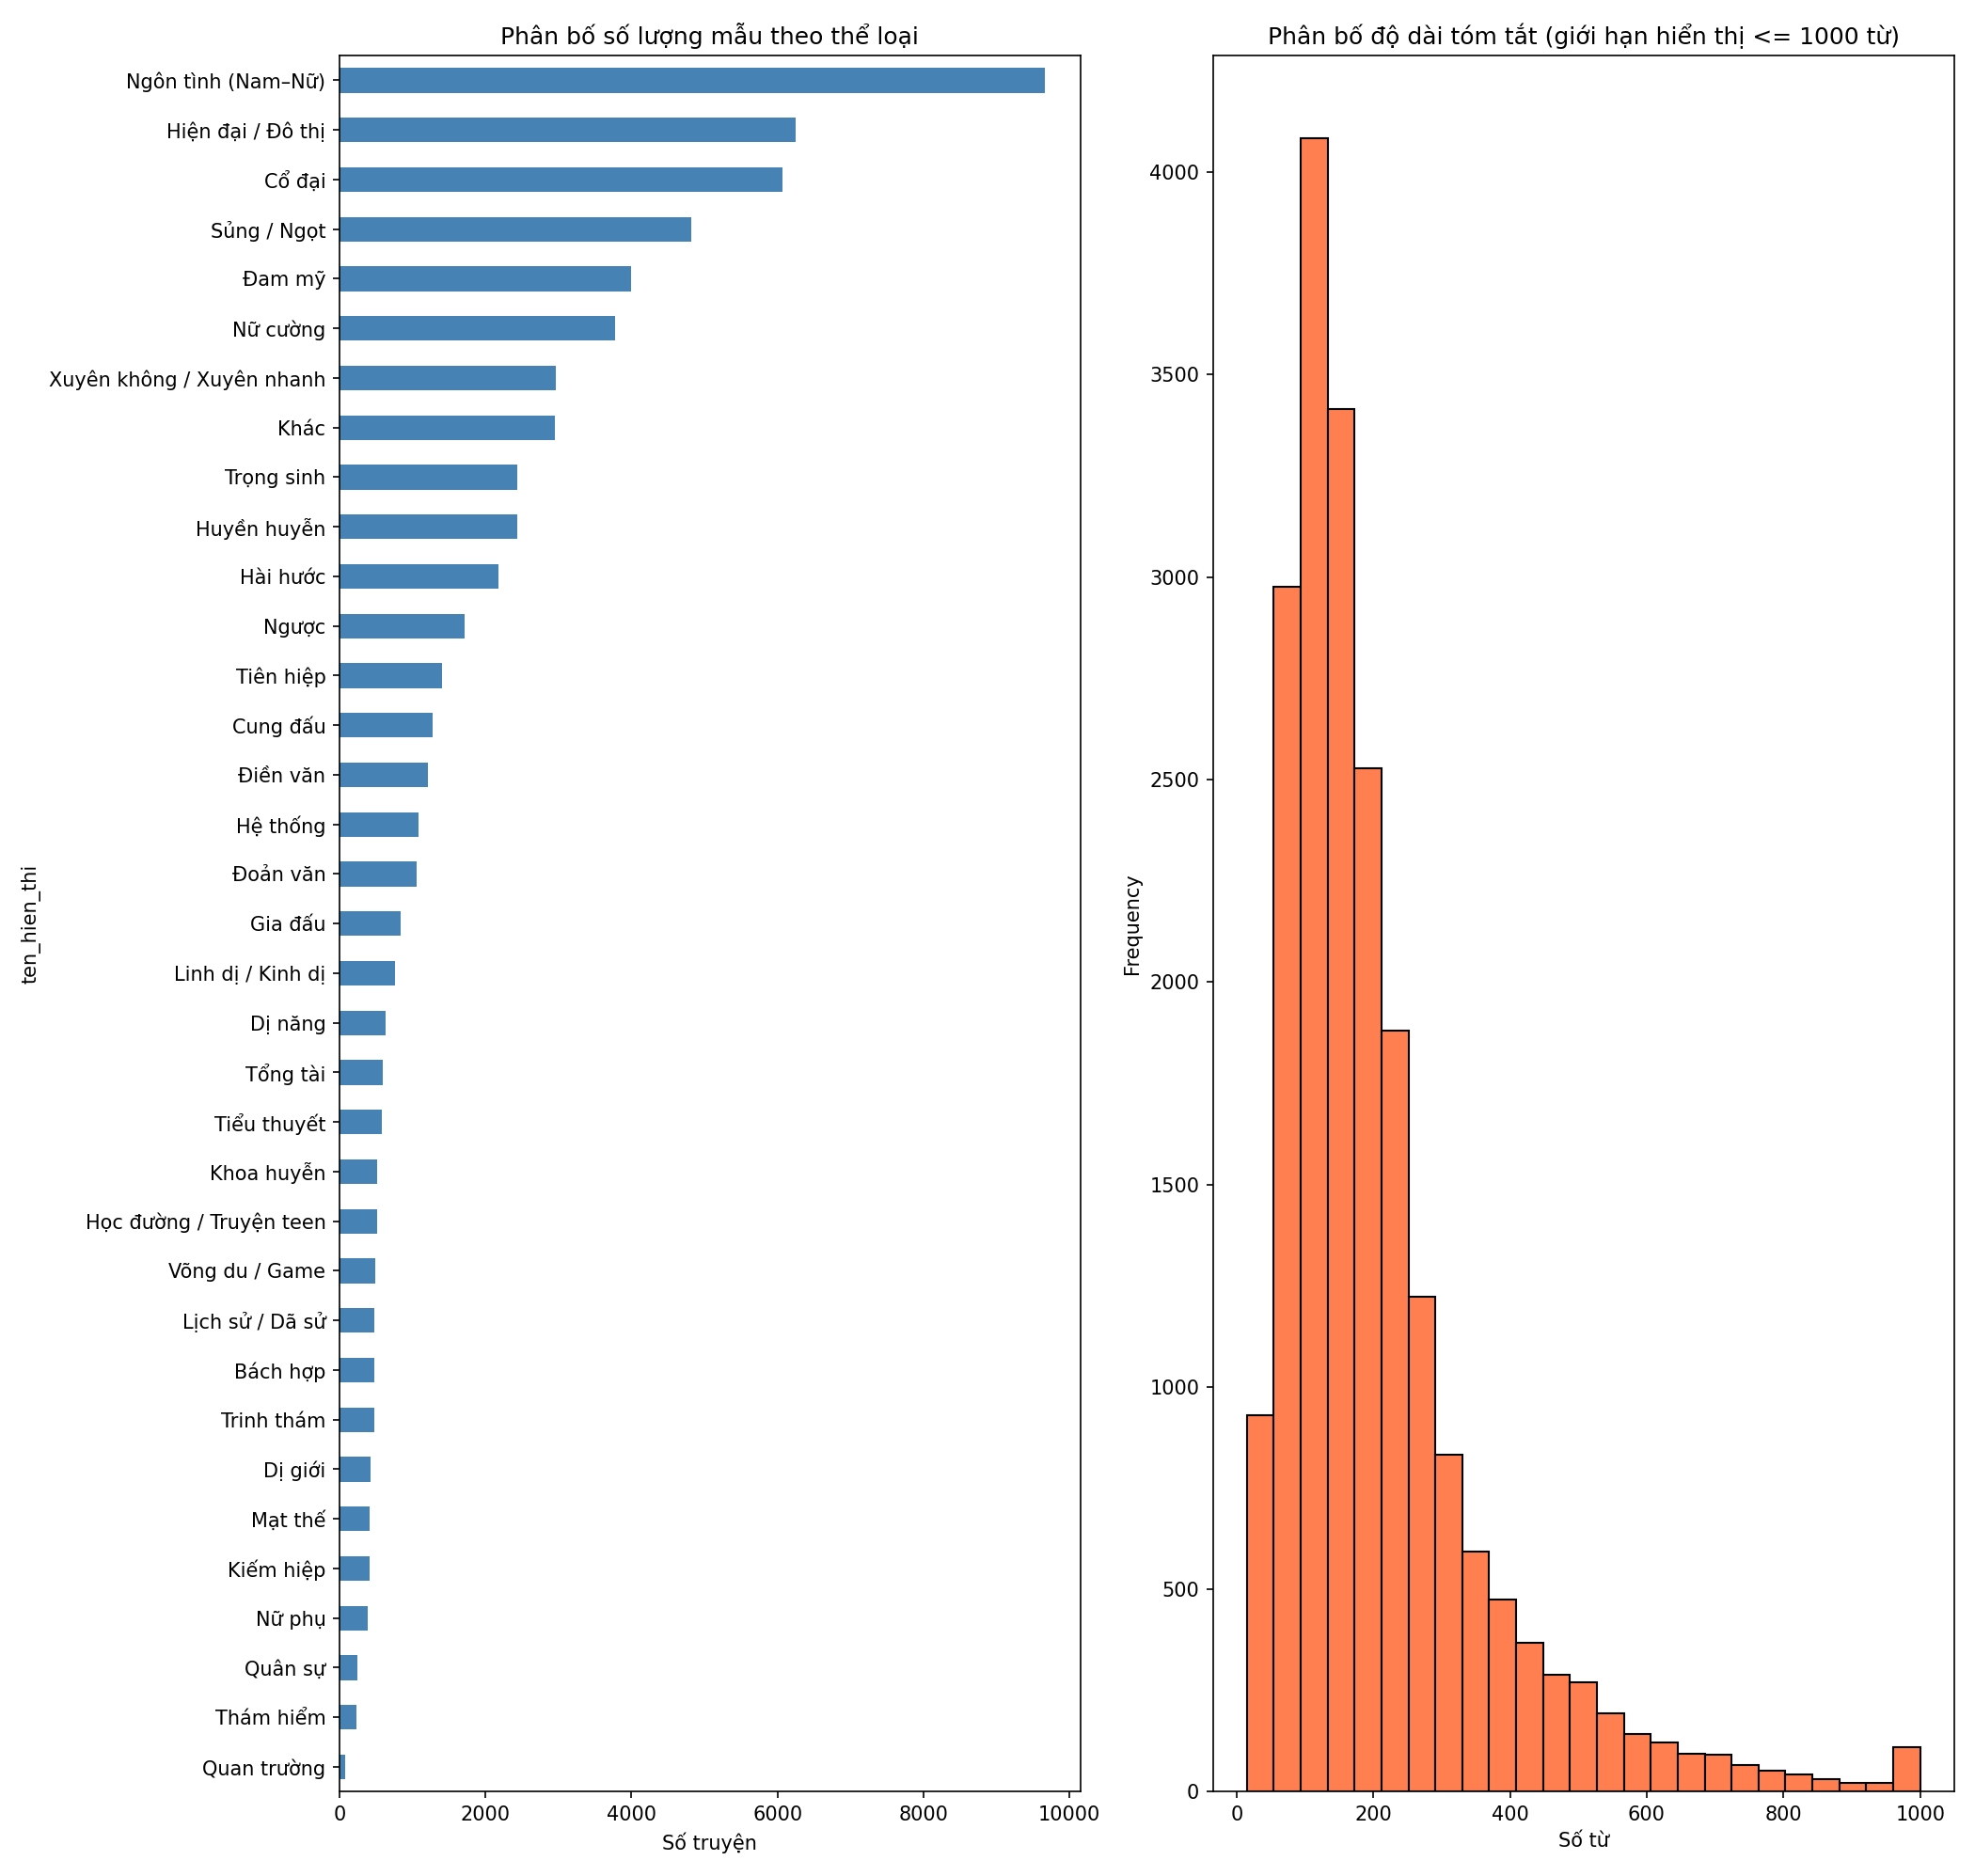

In [5]:
# Ma trận đồng xuất hiện nhãn và vẽ biểu đồ EDA (nếu đã cài matplotlib)
co_occurrence = df_stories[label_cols].T @ df_stories[label_cols]
co_occurrence.index = GENRE_LABELS
co_occurrence.columns = GENRE_LABELS
print("Ma trận đồng xuất hiện giữa các thể loại:")
display(co_occurrence)

try:
    import matplotlib.pyplot as plt

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, max(5, 0.38 * len(GENRE_LABELS))))

    eda_genre_df.set_index("ten_hien_thi")["so_mau"].sort_values().plot(
        kind="barh", ax=axes[0], color="steelblue"
    )
    axes[0].set_title("Phân bố số lượng mẫu theo thể loại")
    axes[0].set_xlabel("Số truyện")

    df_stories["n_words"].clip(upper=1000).plot(
        kind="hist", bins=25, ax=axes[1], color="coral", edgecolor="black"
    )
    axes[1].set_title("Phân bố độ dài tóm tắt (giới hạn hiển thị <= 1000 từ)")
    axes[1].set_xlabel("Số từ")

    plt.tight_layout()
    out_fig = FIGURES_DIR / "eda_overview.png"
    plt.savefig(out_fig, dpi=150)
    plt.close(fig)
    from IPython.display import Image, display
    print(f"Đã lưu biểu đồ tại: {out_fig}")
    display(Image(filename=str(out_fig)))
except ImportError:
    print("Lưu ý: Chưa cài matplotlib nên bỏ qua bước xuất biểu đồ PNG (cài bằng pip install -r requirements.txt).")

## Tổng kết Giai đoạn 1–3 (Thu thập đa nguồn, Chuẩn hóa 35 nhãn & EDA)

- **Quy mô dữ liệu đa nguồn (`58.751` thô $\rightarrow$ `20.852` truyện hợp lệ trên `35` nhãn):** `webtruyen.vn` (`18.230`) làm trục chính, bổ sung thêm 10 thể loại thiếu mẫu từ `truyenfull.live` (`2.069`), `metruyenchu.com.vn` (`418`) và `webnovel.vn` (`135`), lưu tại `data/processed/stories.csv`.
- **Hiệu quả cào bổ sung cho các nhãn hiếm:** `tham_hiem` (`18 -> 235`), `quan_truong` (`36 -> 71`), `quan_su` (`90 -> 246`), `nu_phu` (`119 -> 384`), `lich_su` (`143 -> 477`), `vong_du` (`148 -> 488`), `hoc_duong` (`180 -> 510`), `khoa_huyen` (`203 -> 520`), `mat_the` (`204 -> 417`), `trinh_tham` (`233 -> 471`). Mọi nhãn trong 35 nhãn đều có ít nhất `71` mẫu (`quan_truong`).
- **Đặc trưng bài toán đa nhãn:** `Label cardinality = 3.0601` nhãn/truyện, `Label density = 0.0874`, số nhãn mỗi truyện từ `1` đến `16`; độ dài `summary` dao động `15`–`3.598` từ (trung bình `205.90` từ, trung vị `161` từ).
- **Cặp nhãn đồng xuất hiện mạnh nhất (`35×35`):** `ngon_tinh & hien_dai` (`3.332`), `ngon_tinh & sung` (`3.222`), `ngon_tinh & co_dai` (`3.018`), `nu_cuong & co_dai` (`2.213`), `sung & hien_dai` (`1.964`). Biểu đồ tổng quan lưu tại `outputs/figures/eda_overview.png`.